Number of sensors: 32
Inactive sensors: [1, 5, 9, 13, 17, 21, 25, 29]
Active sensors: 24
Signal matrix shape: (32, 600)
Cubic spline interpolation complete!


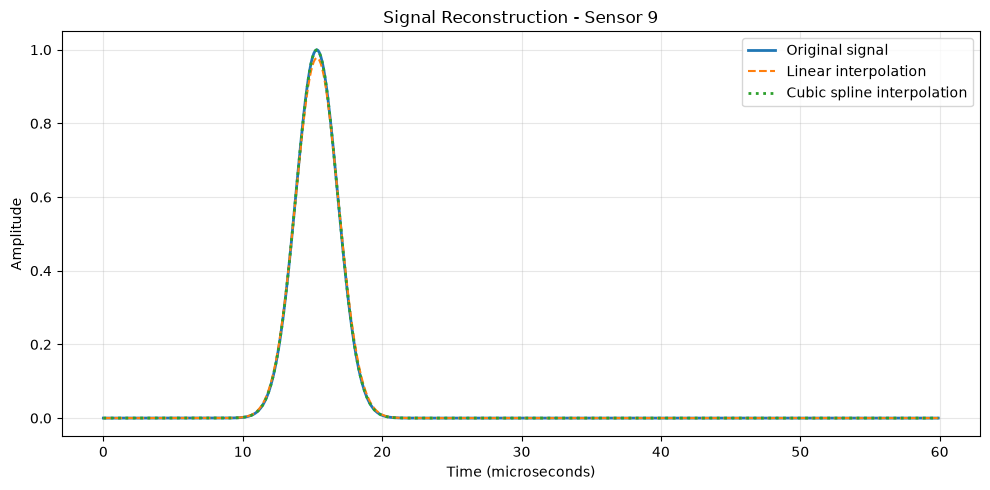

DAS reconstruction complete!


C:\Users\user\AppData\Local\Temp\ipykernel_18044\3950634896.py:195: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


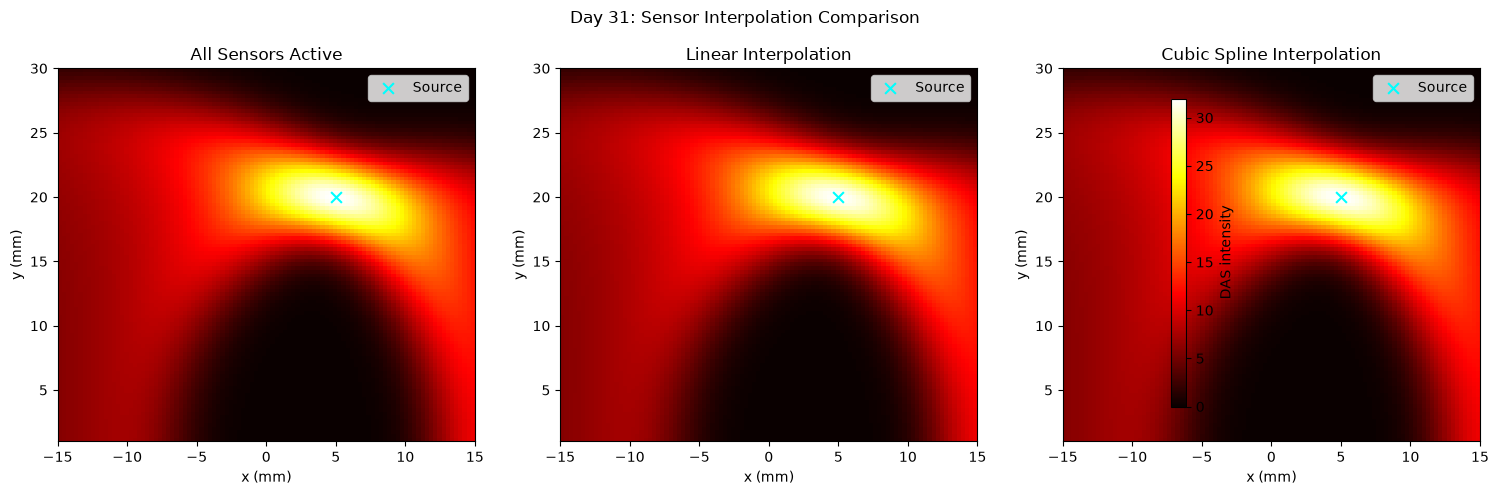


--- Image Metrics vs Full-Sensor Baseline ---
Linear interpolation: {'MAE': 0.021956865000956137, 'RMSE': 0.03271810946243454, 'Max_Absolute_Error': 0.13835454087431742}
Cubic spline interpolation: {'MAE': 0.0040471658549425015, 'RMSE': 0.0064461876578149075, 'Max_Absolute_Error': 0.019544590249953586}

--- Inactive Signal Metrics ---
Linear interpolation: {'MAE': 0.0011534586447801273, 'RMSE': 0.004136427374714731, 'Max_Absolute_Error': 0.04299596036173803}
Cubic spline interpolation: {'MAE': 0.00015405604650551804, 'RMSE': 0.0011045742024590932, 'Max_Absolute_Error': 0.01727057403918475}

Results saved to: ..\outputs\day31_cubic_spline_results.json
Day 31 completed successfully!


In [1]:

import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import CubicSpline

# --------------------------------------------------
# Day 31: Cubic Spline Interpolation for Inactive Sensors
# --------------------------------------------------

# Output directory
output_dir = Path("../outputs")
output_dir.mkdir(parents=True, exist_ok=True)

# 1. Simulation settings
num_sensors = 32
fs = 10e6
duration = 60e-6
c = 1500.0  # Speed of sound (m/s)

time = np.arange(600) / fs
sensor_x = np.linspace(-15e-3, 15e-3, num_sensors)

# Synthetic point source
source_x = 5e-3
source_y = 20e-3
pulse_width = 1.5e-6

# 2. Generate synthetic sensor signals
signals_full = np.zeros((num_sensors, len(time)))

for i, sx in enumerate(sensor_x):
    distance = np.sqrt(
        (sx - source_x)**2 + source_y**2
    )
    arrival_time = distance / c

    signals_full[i] = np.exp(
        -0.5 * ((time - arrival_time) / pulse_width)**2
    )

# 3. Simulate 8 inactive sensors
inactive_indices = np.arange(1, num_sensors, 4)
active_mask = np.ones(num_sensors, dtype=bool)
active_mask[inactive_indices] = False

signals_missing = signals_full.copy()
signals_missing[~active_mask, :] = 0.0

# 4. Linear interpolation (baseline from Day 30)
signals_linear = signals_missing.copy()

for j in range(len(time)):
    signals_linear[:, j] = np.interp(
        sensor_x,
        sensor_x[active_mask],
        signals_missing[active_mask, j]
    )

# 5. Cubic spline interpolation
signals_spline = signals_missing.copy()

spline_model = CubicSpline(
    sensor_x[active_mask],
    signals_missing[active_mask, :],
    axis=0,
    bc_type="natural",
    extrapolate=True
)

signals_spline[~active_mask, :] = spline_model(
    sensor_x[~active_mask]
)

print("Number of sensors:", num_sensors)
print("Inactive sensors:", inactive_indices.tolist())
print("Active sensors:", int(active_mask.sum()))
print("Signal matrix shape:", signals_full.shape)
print("Cubic spline interpolation complete!")

# 6. Plot an example reconstructed sensor signal
sensor_to_plot = int(inactive_indices[2])

plt.figure(figsize=(10, 5))
plt.plot(
    time * 1e6,
    signals_full[sensor_to_plot],
    label="Original signal",
    linewidth=2
)
plt.plot(
    time * 1e6,
    signals_linear[sensor_to_plot],
    "--",
    label="Linear interpolation"
)
plt.plot(
    time * 1e6,
    signals_spline[sensor_to_plot],
    ":",
    label="Cubic spline interpolation",
    linewidth=2
)

plt.xlabel("Time (microseconds)")
plt.ylabel("Amplitude")
plt.title(f"Signal Reconstruction - Sensor {sensor_to_plot}")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    output_dir / "day31_cubic_spline_interpolation.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# 7. Define the image reconstruction grid
x_grid = np.linspace(-15e-3, 15e-3, 100)
y_grid = np.linspace(1e-3, 30e-3, 100)
X, Y = np.meshgrid(x_grid, y_grid)

# 8. Delay-and-Sum reconstruction
def das_reconstruction(sensor_signals):
    image = np.zeros_like(X, dtype=float)

    for i, sx in enumerate(sensor_x):
        distances = np.sqrt((X - sx)**2 + Y**2)
        delays = distances / c

        sampled_signal = np.interp(
            delays.ravel(),
            time,
            sensor_signals[i],
            left=0.0,
            right=0.0
        ).reshape(X.shape)

        image += sampled_signal

    return image

image_full = das_reconstruction(signals_full)
image_linear = das_reconstruction(signals_linear)
image_spline = das_reconstruction(signals_spline)

print("DAS reconstruction complete!")

# 9. Compare reconstructed images
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

images = [
    (image_full, "All Sensors Active"),
    (image_linear, "Linear Interpolation"),
    (image_spline, "Cubic Spline Interpolation")
]

# Use the same color scale for a fair comparison
vmax = max(float(np.max(image_full)), 1e-12)

for ax, (img, title) in zip(axes, images):
    im = ax.imshow(
        img,
        extent=[
            x_grid[0] * 1e3,
            x_grid[-1] * 1e3,
            y_grid[0] * 1e3,
            y_grid[-1] * 1e3
        ],
        origin="lower",
        aspect="auto",
        cmap="hot",
        vmin=0,
        vmax=vmax
    )

    ax.scatter(
        [source_x * 1e3],
        [source_y * 1e3],
        marker="x",
        color="cyan",
        s=60,
        label="Source"
    )

    ax.set_title(title)
    ax.set_xlabel("x (mm)")
    ax.set_ylabel("y (mm)")
    ax.legend(loc="upper right")

fig.colorbar(im, ax=axes, label="DAS intensity", shrink=0.8)
fig.suptitle("Day 31: Sensor Interpolation Comparison")
plt.tight_layout()

plt.savefig(
    output_dir / "day31_reconstruction_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# 10. Quantitative evaluation against full-sensor baseline
def calculate_metrics(reference, estimate):
    error = estimate - reference

    return {
        "MAE": float(np.mean(np.abs(error))),
        "RMSE": float(np.sqrt(np.mean(error**2))),
        "Max_Absolute_Error": float(np.max(np.abs(error)))
    }

linear_metrics = calculate_metrics(image_full, image_linear)
spline_metrics = calculate_metrics(image_full, image_spline)

# Evaluate signal reconstruction at inactive sensors
linear_signal_metrics = calculate_metrics(
    signals_full[~active_mask],
    signals_linear[~active_mask]
)

spline_signal_metrics = calculate_metrics(
    signals_full[~active_mask],
    signals_spline[~active_mask]
)

results = {
    "day": 31,
    "method": "Cubic spline interpolation",
    "num_sensors": int(num_sensors),
    "num_inactive_sensors": int(len(inactive_indices)),
    "inactive_sensor_indices_zero_based": inactive_indices.tolist(),
    "boundary_condition": "natural",
    "image_metrics_vs_full_sensor_baseline": {
        "linear_interpolation": linear_metrics,
        "cubic_spline_interpolation": spline_metrics
    },
    "inactive_signal_metrics": {
        "linear_interpolation": linear_signal_metrics,
        "cubic_spline_interpolation": spline_signal_metrics
    },
    "reference_note": (
        "The full-sensor DAS image and original synthetic signals "
        "are simulation baselines, not experimental ground truth."
    )
}

with open(
    output_dir / "day31_cubic_spline_results.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(results, f, indent=4, ensure_ascii=False)

print("\n--- Image Metrics vs Full-Sensor Baseline ---")
print("Linear interpolation:", linear_metrics)
print("Cubic spline interpolation:", spline_metrics)

print("\n--- Inactive Signal Metrics ---")
print("Linear interpolation:", linear_signal_metrics)
print("Cubic spline interpolation:", spline_signal_metrics)

print("\nResults saved to:", output_dir / "day31_cubic_spline_results.json")
print("Day 31 completed successfully!")
